<a href="https://colab.research.google.com/github/deepti-28/llm-data-analytics-assistant/blob/main/text_to_sql_analytics_assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Conversational Data Analytics Assistant (Text-to-SQL using Generative AI and LLMs)
Pipeline: question -> schema-aware prompt -> LLM writes SQL -> read-only validator -> execute -> auto-repair retries -> chart -> Gradio UI -> evaluation.

**Before running:** click the key icon (Secrets) in the left sidebar of Colab, add a secret named `GEMINI_API_KEY`, and turn on notebook access. Get a free key from Google AI Studio.

## 1. Setup

In [1]:
!pip install -q google-genai gradio pandas matplotlib

In [8]:
import os, re, json, time, sqlite3, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
from google import genai
from google.genai import types

MODEL = "gemini-3.8-flash"   # change if this model name is retired
MAX_ROWS = 200               # row cap added to queries that have no LIMIT

try:
    from google.colab import userdata
    API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    import getpass
    API_KEY = getpass.getpass("Paste your Gemini API key: ")

client = genai.Client(api_key=API_KEY)

Paste your Gemini API key: ··········


## 2. Database (Chinook sample store, SQLite)

In [9]:
DB_PATH = "chinook.db"
URL = "https://github.com/lerocha/chinook-database/raw/master/ChinookDatabase/DataSources/Chinook_Sqlite.sqlite"

if not os.path.exists(DB_PATH):
    try:
        urllib.request.urlretrieve(URL, DB_PATH)
    except Exception as e:
        print("Download failed:", e)
        print("Download Chinook_Sqlite.sqlite manually, upload it to Colab, and rename it to chinook.db")

conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)
print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))
conn.close()

             name
0           Album
1          Artist
2        Customer
3        Employee
4           Genre
5         Invoice
6     InvoiceLine
7       MediaType
8        Playlist
9   PlaylistTrack
10          Track


## 3. Schema extraction (the schema-aware part of the prompt)

In [10]:
def get_schema(db_path=DB_PATH):
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    cur = conn.cursor()
    tables = [r[0] for r in cur.execute(
        "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%'")]
    parts = []
    for t in tables:
        cols = cur.execute(f'PRAGMA table_info("{t}")').fetchall()
        fks = cur.execute(f'PRAGMA foreign_key_list("{t}")').fetchall()
        col_txt = ", ".join(f"{c[1]} {c[2]}" for c in cols)
        line = f"Table {t}({col_txt})"
        if fks:
            line += "\n  Foreign keys: " + "; ".join(f"{f[3]} -> {f[2]}.{f[4]}" for f in fks)
        parts.append(line)
    conn.close()
    return "\n".join(parts)

SCHEMA = get_schema()
print(SCHEMA[:1200], "...")

Table Album(AlbumId INTEGER, Title NVARCHAR(160), ArtistId INTEGER)
  Foreign keys: ArtistId -> Artist.ArtistId
Table Artist(ArtistId INTEGER, Name NVARCHAR(120))
Table Customer(CustomerId INTEGER, FirstName NVARCHAR(40), LastName NVARCHAR(20), Company NVARCHAR(80), Address NVARCHAR(70), City NVARCHAR(40), State NVARCHAR(40), Country NVARCHAR(40), PostalCode NVARCHAR(10), Phone NVARCHAR(24), Fax NVARCHAR(24), Email NVARCHAR(60), SupportRepId INTEGER)
  Foreign keys: SupportRepId -> Employee.EmployeeId
Table Employee(EmployeeId INTEGER, LastName NVARCHAR(20), FirstName NVARCHAR(20), Title NVARCHAR(30), ReportsTo INTEGER, BirthDate DATETIME, HireDate DATETIME, Address NVARCHAR(70), City NVARCHAR(40), State NVARCHAR(40), Country NVARCHAR(40), PostalCode NVARCHAR(10), Phone NVARCHAR(24), Fax NVARCHAR(24), Email NVARCHAR(60))
  Foreign keys: ReportsTo -> Employee.EmployeeId
Table Genre(GenreId INTEGER, Name NVARCHAR(120))
Table Invoice(InvoiceId INTEGER, CustomerId INTEGER, InvoiceDate DATE

## 4. Prompt, few-shot examples, and structured (JSON) output

In [14]:
from google.genai import errors

# 1) Discover which Gemini models your key can actually use ("lite" ones first, they are usually less busy)
candidates = []
for m in client.models.list():
    name = m.name.replace("models/", "")
    actions = getattr(m, "supported_actions", None) or []
    skip = ("image", "tts", "live", "audio", "embedding")
    if "flash" in name and "generateContent" in actions and not any(s in name for s in skip):
        candidates.append(name)
candidates.sort(key=lambda n: ("lite" not in n, n))
MODELS = candidates[:5]
print("Models to try:", MODELS)

PROMPT_TEMPLATE = """You are an expert SQLite data analyst. Convert the user's question into ONE SQLite query.

Rules:
- Use only the tables and columns in the schema below.
- Output a single SELECT (or WITH ... SELECT) query. Never modify data.
- Use SQLite syntax (for example strftime for dates).
- Return only the columns needed to answer the question, with readable aliases.
- Respond with JSON only, in the form {"sql": "<query>"}.

Schema:
<<SCHEMA>>

Examples:
Q: How many employees are there?
{"sql": "SELECT COUNT(*) AS employee_count FROM Employee"}
Q: What are the 3 longest tracks?
{"sql": "SELECT Name, Milliseconds FROM Track ORDER BY Milliseconds DESC LIMIT 3"}
Q: Show total sales for each month of 2012.
{"sql": "SELECT strftime('%Y-%m', InvoiceDate) AS month, SUM(Total) AS total_sales FROM Invoice WHERE strftime('%Y', InvoiceDate) = '2012' GROUP BY month ORDER BY month"}
"""
SYSTEM_PROMPT = PROMPT_TEMPLATE.replace("<<SCHEMA>>", SCHEMA)


def parse_sql(text):
    text = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    return json.loads(text)["sql"]


def generate_sql(question, prev_sql=None, prev_error=None):
    prompt = f"Question: {question}"
    if prev_sql:
        prompt += (f"\n\nYour previous query failed.\nQuery: {prev_sql}\nError: {prev_error}\n"
                   "Return a corrected query as JSON.")

    last_err = None
    for model in MODELS:                      # move to the next model if one is busy or unavailable
        for wait in (2, 6):                   # two quick tries per model
            try:
                resp = client.models.generate_content(
                    model=model,
                    contents=prompt,
                    config=types.GenerateContentConfig(
                        system_instruction=SYSTEM_PROMPT,
                        response_mime_type="application/json",
                        temperature=0,
                    ),
                )
                return parse_sql(resp.text)
            except errors.ServerError as e:                       # 503 overloaded, 500, etc.
                last_err = e
                print(f"{model} busy, retrying in {wait}s...")
                time.sleep(wait)
            except errors.ClientError as e:
                if e.code in (404, 429):                          # model retired or quota hit: try next model
                    last_err = e
                    print(f"{model} unavailable ({e.code}), trying next model...")
                    break
                raise                                             # bad key, bad request: stop and show it
    raise RuntimeError(f"All models failed. Last error: {last_err}")


print(generate_sql("How many customers are there?"))

Models to try: ['gemini-2.5-flash-lite', 'gemini-3.1-flash-lite', 'gemini-3.1-flash-lite-preview', 'gemini-3.5-flash-lite', 'gemini-flash-lite-latest']
gemini-2.5-flash-lite unavailable (404), trying next model...
SELECT COUNT(*) AS customer_count FROM Customer


## 5. Read-only SQL validator

In [15]:
FORBIDDEN = re.compile(
    r"\b(insert|update|delete|drop|alter|create|replace|attach|detach|pragma|vacuum|truncate)\b", re.I)

def validate_sql(sql):
    s = sql.strip().rstrip(";").strip()
    if ";" in s:
        raise ValueError("Multiple statements are not allowed.")
    if not re.match(r"^(select|with)\b", s, re.I):
        raise ValueError("Only SELECT queries are allowed.")
    m = FORBIDDEN.search(s)
    if m:
        raise ValueError(f"Forbidden keyword: {m.group(0)}")
    if not re.search(r"\blimit\b", s, re.I):
        s += f" LIMIT {MAX_ROWS}"
    return s

# quick checks
for q in ["SELECT * FROM Customer", "DROP TABLE Customer", "SELECT 1; DELETE FROM Customer"]:
    try:
        print("OK     :", validate_sql(q))
    except ValueError as e:
        print("BLOCKED:", q, "->", e)

OK     : SELECT * FROM Customer LIMIT 200
BLOCKED: DROP TABLE Customer -> Only SELECT queries are allowed.
BLOCKED: SELECT 1; DELETE FROM Customer -> Multiple statements are not allowed.


## 6. Execute with automatic error-repair retries

In [16]:
def run_query(sql, db_path=DB_PATH):
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)   # second layer of protection
    try:
        return pd.read_sql_query(sql, conn)
    finally:
        conn.close()


def ask(question, max_retries=2):
    last_sql, err = None, None
    for attempt in range(1, max_retries + 2):
        try:
            raw = generate_sql(question, last_sql, err)
            last_sql = raw
            sql = validate_sql(raw)
            df = run_query(sql)
            return {"question": question, "sql": sql, "df": df, "attempts": attempt, "error": None}
        except Exception as e:
            err = f"{type(e).__name__}: {e}"
            time.sleep(1)
    return {"question": question, "sql": last_sql, "df": None, "attempts": max_retries + 1, "error": err}

## 7. Auto-generated charts

gemini-2.5-flash-lite unavailable (404), trying next model...
SELECT BillingCountry, SUM(Total) AS TotalRevenue FROM Invoice GROUP BY BillingCountry ORDER BY TotalRevenue DESC LIMIT 5 | attempts: 1 | error: None


,BillingCountry,TotalRevenue
0,USA,523.06
1,Canada,303.96
2,France,195.10
3,Brazil,190.10
4,Germany,156.48


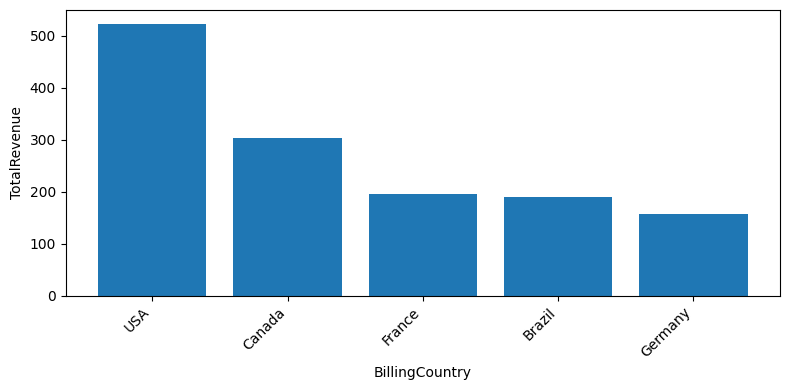

In [17]:
def auto_chart(df):
    if df is None or df.shape[1] < 2 or not (2 <= len(df) <= 50):
        return None
    x, y = df.columns[0], df.columns[1]
    if not pd.api.types.is_numeric_dtype(df[y]):
        return None
    fig, ax = plt.subplots(figsize=(8, 4))
    if any(k in x.lower() for k in ("year", "month", "date")):
        ax.plot(df[x].astype(str), df[y], marker="o")
    else:
        ax.bar(df[x].astype(str), df[y])
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.close(fig)
    return fig

res = ask("Top 5 countries by total invoice revenue")
print(res["sql"], "| attempts:", res["attempts"], "| error:", res["error"])
display(res["df"])
display(auto_chart(res["df"]))

## 8. Gradio interface

In [18]:
def gradio_fn(question):
    if not question.strip():
        return "", None, None, "Please enter a question."
    res = ask(question)
    if res["error"]:
        return res["sql"] or "", None, None, f"Failed after {res['attempts']} attempts: {res['error']}"
    return res["sql"], res["df"], auto_chart(res["df"]), f"Answered in {res['attempts']} attempt(s)."

demo = gr.Interface(
    fn=gradio_fn,
    inputs=gr.Textbox(label="Ask a business question", lines=2),
    outputs=[
        gr.Code(label="Generated SQL", language="sql"),
        gr.Dataframe(label="Result"),
        gr.Plot(label="Chart"),
        gr.Textbox(label="Status"),
    ],
    examples=[
        ["Which 5 countries generate the most revenue?"],
        ["Show total sales for each year"],
        ["Which genres have the most tracks?"],
    ],
    title="Conversational Data Analytics Assistant (Text-to-SQL)",
    flagging_mode="never",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fb95f50d411048b4a2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 9. Evaluation (the part to talk about in interviews)
Each question has a hand-written gold SQL query. A prediction counts as correct when its result set matches the gold result set (row order ignored, numbers rounded to 2 decimals).
Start with these 15, then extend to about 30 (10 per tier). **Run each gold query once yourself and sanity-check the output before trusting the score.**

In [19]:
TEST_SET = [
    # ---- easy ----
    ("easy", "How many customers are there?", "SELECT COUNT(*) FROM Customer"),
    ("easy", "How many tracks are there?", "SELECT COUNT(*) FROM Track"),
    ("easy", "List all genre names.", "SELECT Name FROM Genre"),
    ("easy", "What is the total revenue from all invoices?", "SELECT SUM(Total) FROM Invoice"),
    ("easy", "How many albums are there?", "SELECT COUNT(*) FROM Album"),
    # ---- medium ----
    ("medium", "What are the top 5 billing countries by total invoice revenue? Show country and revenue.",
     "SELECT BillingCountry, SUM(Total) FROM Invoice GROUP BY BillingCountry ORDER BY SUM(Total) DESC LIMIT 5"),
    ("medium", "Which 3 artists have the most albums? Show artist name and album count.",
     "SELECT ar.Name, COUNT(*) FROM Artist ar JOIN Album al ON al.ArtistId = ar.ArtistId GROUP BY ar.ArtistId ORDER BY COUNT(*) DESC LIMIT 3"),
    ("medium", "What is the average invoice total for each billing country? Show country and average.",
     "SELECT BillingCountry, AVG(Total) FROM Invoice GROUP BY BillingCountry"),
    ("medium", "How many invoices were issued in each year? Show year and count.",
     "SELECT strftime('%Y', InvoiceDate), COUNT(*) FROM Invoice GROUP BY strftime('%Y', InvoiceDate)"),
    ("medium", "List the first and last names of customers from Brazil.",
     "SELECT FirstName, LastName FROM Customer WHERE Country = 'Brazil'"),
    # ---- hard ----
    ("hard", "Show the first name, last name and total spent of the top 5 customers by total spending.",
     "SELECT c.FirstName, c.LastName, SUM(i.Total) FROM Customer c JOIN Invoice i ON i.CustomerId = c.CustomerId GROUP BY c.CustomerId ORDER BY SUM(i.Total) DESC LIMIT 5"),
    ("hard", "What are the top 3 genres by total sales revenue (unit price times quantity)? Show genre and revenue.",
     "SELECT g.Name, SUM(il.UnitPrice * il.Quantity) FROM InvoiceLine il JOIN Track t ON t.TrackId = il.TrackId JOIN Genre g ON g.GenreId = t.GenreId GROUP BY g.GenreId ORDER BY SUM(il.UnitPrice * il.Quantity) DESC LIMIT 3"),
    ("hard", "How many customers have spent more than the average total spend per customer?",
     "SELECT COUNT(*) FROM (SELECT CustomerId, SUM(Total) AS s FROM Invoice GROUP BY CustomerId) WHERE s > (SELECT AVG(s2) FROM (SELECT SUM(Total) AS s2 FROM Invoice GROUP BY CustomerId))"),
    ("hard", "Which sales support rep has the highest total invoice revenue from their customers? Show first name, last name and total revenue.",
     "SELECT e.FirstName, e.LastName, SUM(i.Total) FROM Employee e JOIN Customer c ON c.SupportRepId = e.EmployeeId JOIN Invoice i ON i.CustomerId = c.CustomerId GROUP BY e.EmployeeId ORDER BY SUM(i.Total) DESC LIMIT 1"),
    ("hard", "What is the average track length in minutes for each of the 3 genres with the most tracks? Show genre and average minutes.",
     "SELECT g.Name, AVG(t.Milliseconds) / 60000.0 FROM Track t JOIN Genre g ON g.GenreId = t.GenreId WHERE g.GenreId IN (SELECT GenreId FROM Track GROUP BY GenreId ORDER BY COUNT(*) DESC LIMIT 3) GROUP BY g.GenreId"),
]


def norm_val(v):
    try:
        return f"{float(v):.2f}"
    except (TypeError, ValueError):
        return str(v)


def result_signature(df):
    return sorted(tuple(norm_val(v) for v in row) for row in df.itertuples(index=False))


records = []
for level, question, gold_sql in TEST_SET:
    gold_df = run_query(gold_sql)
    res = ask(question)
    correct = bool(res["df"] is not None and result_signature(res["df"]) == result_signature(gold_df))
    records.append({"level": level, "question": question, "correct": correct,
                    "attempts": res["attempts"], "generated_sql": res["sql"],
                    "gold_sql": gold_sql, "error": res["error"]})
    print(("PASS" if correct else "FAIL"), "|", level, "|", question)
    time.sleep(6)   # stay under free-tier rate limits

results = pd.DataFrame(records)
results.to_csv("eval_results.csv", index=False)

gemini-2.5-flash-lite unavailable (404), trying next model...
PASS | easy | How many customers are there?
gemini-2.5-flash-lite unavailable (404), trying next model...
PASS | easy | How many tracks are there?
gemini-2.5-flash-lite unavailable (404), trying next model...
PASS | easy | List all genre names.
gemini-2.5-flash-lite unavailable (404), trying next model...
PASS | easy | What is the total revenue from all invoices?
gemini-2.5-flash-lite unavailable (404), trying next model...
PASS | easy | How many albums are there?
gemini-2.5-flash-lite unavailable (404), trying next model...
PASS | medium | What are the top 5 billing countries by total invoice revenue? Show country and revenue.
gemini-2.5-flash-lite unavailable (404), trying next model...
gemini-3.1-flash-lite busy, retrying in 2s...
PASS | medium | Which 3 artists have the most albums? Show artist name and album count.
gemini-2.5-flash-lite unavailable (404), trying next model...
PASS | medium | What is the average invoice 

In [20]:
summary = results.groupby("level")["correct"].agg(["sum", "count", "mean"]).reindex(["easy", "medium", "hard"])
summary["accuracy_%"] = (summary["mean"] * 100).round(1)
print(summary[["sum", "count", "accuracy_%"]])
print(f"\nOverall execution accuracy: {results['correct'].mean() * 100:.1f}% on {len(results)} questions")
print("Fixed by auto-retry:", int(((results["attempts"] > 1) & results["correct"]).sum()))

# Failure analysis: read these and note why each failed (wrong join, wrong columns, ambiguity, ...)
display(results.loc[~results["correct"], ["level", "question", "generated_sql", "gold_sql", "error"]])

        sum  count  accuracy_%
level                         
easy      5      5       100.0
medium    5      5       100.0
hard      5      5       100.0

Overall execution accuracy: 100.0% on 15 questions
Fixed by auto-retry: 0


,level,question,generated_sql,gold_sql,error
